# Análise Exploratória de Risco — Behavior Score

**Objetivo:** EDA orientada a comportamento financeiro, discretização de variáveis, mensuração univariada de risco (WoE/IV), estabilidade de safras e diagnóstico de multicolinearidade para a mesa de crédito.

**Base:** `data/dataset_trat.csv` (30.000 clientes, safras 2005-10 a 2006-07, target `default`).

**Padrão visual:** clean corporativo, paleta monocromática de verdes.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# ==============================================================================
# CONFIGURAÇÃO DE PALETA CORPORATIVA: TONALIDADES DE VERDE
# ==============================================================================
GREEN_DARK   = "#1B4D3E"  # Verde Floresta Profundo (Ênfase/Linhas críticas)
GREEN_MID    = "#2E8B57"  # SeaGreen / Esmeralda (Barras principais)
GREEN_LIGHT  = "#66BB6A"  # Verde Claro Médio
GREEN_PALE   = "#A3E4D7"  # Menta Pálido (Fundos/Volumes secundários)
GREEN_ACCENT = "#0E6251"  # Verde Petróleo (Destaques executivos)

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.sans-serif": "DejaVu Sans",
    "font.size": 11,
    "axes.edgecolor": "#D5D8DC",
    "axes.linewidth": 0.8,
})

TARGET = "default"

## 1. Funções Core do Pipeline

Cálculo de WoE/IV com discretização em quantis, tratamento de nulos em bin dedicado e *Laplace smoothing*; funções de visualização executiva.

In [2]:
# ==============================================================================
# 1. FUNÇÃO CORE: CÁLCULO DE WEIGHT OF EVIDENCE (WOE) E INFORMATION VALUE (IV)
# ==============================================================================
def calcular_woe_iv(df: pd.DataFrame, feature: str, target: str, bins: int = 10, is_continuous: bool = True):
    """
    Discretiza atributos contínuos em quantis, preserva valores nulos em categoria dedicada
    e calcula a tabela de contingência com WoE e IV.
    """
    tmp = df[[feature, target]].copy()
    tmp["bin"] = tmp[feature].fillna("MISSING").astype(object)

    if is_continuous:
        mask_valid = tmp[feature].notnull()
        try:
            tmp.loc[mask_valid, "bin"] = pd.qcut(
                tmp.loc[mask_valid, feature],
                q=bins,
                duplicates="drop"
            ).astype(str)
        except Exception:
            tmp.loc[mask_valid, "bin"] = pd.cut(
                tmp.loc[mask_valid, feature],
                bins=bins,
                duplicates="drop"
            ).astype(str)

    total_goods = (tmp[target] == 0).sum()
    total_bads = (tmp[target] == 1).sum()

    agg = tmp.groupby("bin", observed=False).agg(
        total=(target, "count"),
        bads=(target, "sum"),
        goods=(target, lambda x: (x == 0).sum()),
        bad_rate=(target, "mean")
    ).reset_index()

    # Laplace smoothing contra log(0) e divisões indefinidas
    agg["dist_good"] = (agg["goods"] + 0.5) / (total_goods + 1.0)
    agg["dist_bad"] = (agg["bads"] + 0.5) / (total_bads + 1.0)

    # Convenção clássica de crédito: ln(Good% / Bad%)
    agg["woe"] = np.log(agg["dist_good"] / agg["dist_bad"])
    agg["iv_bin"] = (agg["dist_good"] - agg["dist_bad"]) * agg["woe"]

    total_iv = agg["iv_bin"].sum()
    return agg, total_iv

In [3]:
# ==============================================================================
# 2. ESTABILIDADE DE SAFRA (VOLUME ATIVO VS. BAD RATE TEMPORAL)
# ==============================================================================
def plot_estabilidade_safra(df: pd.DataFrame, col_safra: str, target: str):
    """
    Avalia se variações na taxa de inadimplência decorrem de choques macroeconômicos
    ou relaxamento na política de concessão/expansão de carteira.
    """
    safra_summary = df.groupby(col_safra, observed=False).agg(
        volume=(target, "count"),
        bad_rate=(target, "mean")
    ).reset_index()

    fig, ax1 = plt.subplots(figsize=(11, 5))
    ax2 = ax1.twinx()

    ax1.bar(
        safra_summary[col_safra],
        safra_summary["volume"],
        color=GREEN_PALE,
        edgecolor=GREEN_MID,
        alpha=0.7,
        label="Volume Ativo"
    )
    ax2.plot(
        safra_summary[col_safra],
        safra_summary["bad_rate"] * 100,
        color=GREEN_DARK,
        marker="o",
        linewidth=2.5,
        label="Bad Rate (%)"
    )

    ax1.set_xlabel("Safra de Referência", fontweight="bold", color=GREEN_DARK)
    ax1.set_ylabel("Volume de Clientes Ativos", color=GREEN_MID, fontweight="bold")
    ax2.set_ylabel("Taxa de Default (%)", color=GREEN_DARK, fontweight="bold")
    ax1.grid(False)
    ax2.grid(True, linestyle=":", alpha=0.6)
    plt.xticks(rotation=45)
    plt.title("Estabilidade de Risco no Tempo: Volume vs. Taxa de Default", fontsize=13, fontweight="bold", pad=15)
    plt.tight_layout()
    plt.show()

In [4]:
# ==============================================================================
# 3. SCREENING DE PODER DISCRIMINATIVO (RANKING DE IV EM VERDE MONOCROMÁTICO)
# ==============================================================================
def plot_ranking_iv(df: pd.DataFrame, features: list, target: str):
    """
    Ordena variáveis pelo Information Value em gradientes de verde institucional.
    """
    iv_dict = {col: calcular_woe_iv(df, col, target)[1] for col in features}
    iv_df = pd.DataFrame(list(iv_dict.items()), columns=["Feature", "IV"]).sort_values("IV", ascending=True)

    cores = []
    for val in iv_df["IV"]:
        if val < 0.02:
            cores.append("#D4EFDF")   # Inexpressivo (<0.02)
        elif val < 0.10:
            cores.append("#A9DFBF")   # Fraco (0.02 - 0.10)
        elif val < 0.30:
            cores.append("#52BE80")   # Médio (0.10 - 0.30)
        elif val <= 0.50:
            cores.append("#1E8449")   # Forte Ideal (0.30 - 0.50)
        else:
            cores.append("#114B27")   # Suspeito / Alerta de Leakage (>0.50)

    fig, ax = plt.subplots(figsize=(10, max(5, len(features) * 0.45)))
    ax.barh(iv_df["Feature"], iv_df["IV"], color=cores, edgecolor=GREEN_DARK, linewidth=0.6)

    ax.axvline(0.02, color=GREEN_LIGHT, linestyle=":", label="Mínimo Relevante (0.02)")
    ax.axvline(0.10, color=GREEN_MID, linestyle="--", label="Preditores Médios (0.10)")
    ax.axvline(0.30, color=GREEN_DARK, linestyle="--", label="Preditores Fortes (0.30)")
    ax.axvline(0.50, color=GREEN_ACCENT, linestyle="-", label="Alerta de Vazamento (>0.50)")

    ax.set_xlabel("Information Value (IV)", fontweight="bold", color=GREEN_DARK)
    ax.set_title("Screening Univariado: Information Value (IV)", fontsize=13, fontweight="bold", pad=15)
    ax.legend(loc="lower right", frameon=True)
    plt.tight_layout()
    plt.show()
    return iv_df.sort_values("IV", ascending=False).reset_index(drop=True)

In [5]:
# ==============================================================================
# 4. CURVA DE MONOTONICIDADE E ESTRATIFICAÇÃO POR FAIXA (WOE & BAD RATE)
# ==============================================================================
def plot_curva_monotonicidade(tabela_woe: pd.DataFrame, feature_name: str, total_iv: float):
    """
    Exibe a concordância monotônica entre faixas de comportamento, inadimplência e WoE.
    """
    fig, ax1 = plt.subplots(figsize=(11, 5))
    ax2 = ax1.twinx()

    x = np.arange(len(tabela_woe))

    ax1.bar(
        x,
        tabela_woe["bad_rate"] * 100,
        color=GREEN_MID,
        alpha=0.65,
        width=0.45,
        label="Bad Rate (%)"
    )
    ax2.plot(
        x,
        tabela_woe["woe"],
        color=GREEN_DARK,
        marker="s",
        markersize=6,
        linewidth=2.5,
        label="WoE [ln(Good%/Bad%)]"
    )

    ax1.set_xticks(x)
    ax1.set_xticklabels(tabela_woe["bin"], rotation=35, ha="right")
    ax1.set_ylabel("Taxa de Default (% Bad)", color=GREEN_MID, fontweight="bold")
    ax2.set_ylabel("Weight of Evidence (WoE)", color=GREEN_DARK, fontweight="bold")
    ax1.set_title(f"Monotonicidade e Risco: {feature_name} (IV: {total_iv:.3f})", fontsize=12, fontweight="bold", pad=15)

    ax1.grid(False)
    ax2.grid(True, linestyle=":", alpha=0.5)
    plt.tight_layout()
    plt.show()

In [6]:
# ==============================================================================
# 5. MATRIZ DE CORRELAÇÃO DE SPEARMAN (COMBATE À MULTICOLINEARIDADE)
# ==============================================================================
def plot_matriz_spearman(df: pd.DataFrame, top_features: list):
    """
    Matriz de correlação não-linear para evitar atributos comportamentais redundantes.
    """
    corr, _ = spearmanr(df[top_features].dropna())
    corr_df = pd.DataFrame(corr, index=top_features, columns=top_features)

    plt.figure(figsize=(9, 7))
    mask = np.triu(np.ones_like(corr_df, dtype=bool))
    cmap_verdes = sns.light_palette(GREEN_DARK, as_cmap=True)

    sns.heatmap(
        corr_df,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap=cmap_verdes,
        vmin=0,
        vmax=1,
        linewidths=0.6,
        cbar_kws={"shrink": .8}
    )
    plt.title("Matriz de Correlação de Spearman (Verificação de Redundância)", fontsize=12, fontweight="bold", pad=15)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 2. Carga e Visão Geral da Base

In [7]:
df = pd.read_csv("../data/dataset_trat.csv", sep=";")

df["SAFRA_LABEL"] = df["SAFRA"].astype(str).str[:4] + "-" + df["SAFRA"].astype(str).str[4:]
df = df.sort_values(["SAFRA", "ID"]).reset_index(drop=True)

print(f"Dimensões: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Taxa de default global: {df[TARGET].mean():.2%}")
print(f"Valores ausentes totais: {df.isna().sum().sum()}")
df.head()

Dimensões: 30,000 linhas x 27 colunas
Taxa de default global: 22.12%
Valores ausentes totais: 0


,ID,SAFRA,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,...,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default,SAFRA_LABEL
0,1,200510,20000,2,2,1,24,2,2,-1,...,0,0,0,689,0,0,0,0,1,2005-10
1,2,200510,120000,2,2,2,26,-1,2,0,...,3455,3261,0,1000,1000,1000,0,2000,1,2005-10
2,3,200510,90000,2,2,2,34,0,0,0,...,14948,15549,1518,1500,1000,1000,1000,5000,0,2005-10
3,4,200510,50000,2,2,1,37,0,0,0,...,28959,29547,2000,2019,1200,1100,1069,1000,0,2005-10
4,5,200510,50000,1,2,1,57,-1,0,-1,...,19146,19131,2000,36681,10000,9000,689,679,0,2005-10


In [8]:
df[[TARGET, "LIMIT_BAL", "AGE", "PAY_0", "BILL_AMT1", "PAY_AMT1"]].describe().T

,count,mean,std,min,25%,50%,75%,max
default,30000.0,0.221200,0.415062,0.0,0.00,0.0,0.0,1.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.0,1000000.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.0,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.0,8.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.0,964511.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.0,873552.0


## 3. Engenharia de Atributos Comportamentais

Derivação de indicadores de utilização de limite, comprometimento de pagamento, frequência de atrasos e uso de rotativo — os principais vetores de *Behavior Score*.

In [9]:
# Utilização do limite no mês mais recente
df["UTILIZACAO"] = (df["BILL_AMT1"] / df["LIMIT_BAL"].replace(0, np.nan)).clip(0, 2)

# Percentual do saldo faturado que foi pago
df["PCT_PAGAMENTO"] = (df["PAY_AMT1"] / df["BILL_AMT1"].replace(0, np.nan)).clip(0, 2)

# Frequência de atrasos (dias de atraso > 0) nos 6 meses
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
df["FREQ_ATRASO"] = (df[pay_cols] > 0).sum(axis=1)

# Permanência máxima em atraso observada
df["MAX_ATRASO"] = df[pay_cols].max(axis=1)

# Tendência de utilização (mês atual vs. média histórica)
bill_cols = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]
df["UTIL_MEDIA"] = (df[bill_cols].mean(axis=1) / df["LIMIT_BAL"].replace(0, np.nan)).clip(0, 2)

# Saldo rotativo médio normalizado pelo limite
payment_ratio = df[bill_cols].values / (df[bill_cols].shift(axis=1).fillna(df[bill_cols]).values + 1)
df["ROTATIVO_MEDIO"] = (1 - np.clip(np.nanmean(payment_ratio, axis=1), 0, 1))

# Idade do relacionamento aproximada por faixa de limite
df["LIMIT_PER_CAPITA"] = df["LIMIT_BAL"] / df["AGE"].replace(0, np.nan)

print("Atributos comportamentais derivados:")
print(["UTILIZACAO", "PCT_PAGAMENTO", "FREQ_ATRASO", "MAX_ATRASO", "UTIL_MEDIA", "ROTATIVO_MEDIO", "LIMIT_PER_CAPITA"])
df[["UTILIZACAO", "PCT_PAGAMENTO", "FREQ_ATRASO", "MAX_ATRASO", "UTIL_MEDIA", "ROTATIVO_MEDIO", "LIMIT_PER_CAPITA"]].describe().T

Atributos comportamentais derivados:
['UTILIZACAO', 'PCT_PAGAMENTO', 'FREQ_ATRASO', 'MAX_ATRASO', 'UTIL_MEDIA', 'ROTATIVO_MEDIO', 'LIMIT_PER_CAPITA']


,count,mean,std,min,25%,50%,75%,max
UTILIZACAO,30000.0,0.422871,0.404623,0.000000,0.022032,0.313994,0.829843,2.000000
PCT_PAGAMENTO,27992.0,0.328093,0.567086,0.000000,0.036641,0.058713,0.258173,2.000000
FREQ_ATRASO,30000.0,0.834200,1.554303,0.000000,0.000000,0.000000,1.000000,6.000000
MAX_ATRASO,30000.0,0.438733,1.345154,-2.000000,0.000000,0.000000,2.000000,8.000000
UTIL_MEDIA,30000.0,0.372851,0.349678,0.000000,0.029997,0.284834,0.687929,2.000000
ROTATIVO_MEDIO,29979.0,0.123948,0.267067,0.000000,0.000000,0.000000,0.091374,1.000000
LIMIT_PER_CAPITA,30000.0,4829.597658,3712.571105,161.290323,1818.181818,4000.000000,6896.551724,26785.714286


## 4. Estabilidade Temporal de Safras (Bad Rate vs. Volume)

Leitura: se o aumento do default coincide com expansão de volume, há indício de **seleção adversa** (relaxamento de política). Com volume estável, a causa tende a ser **exógena** (estresse macro).

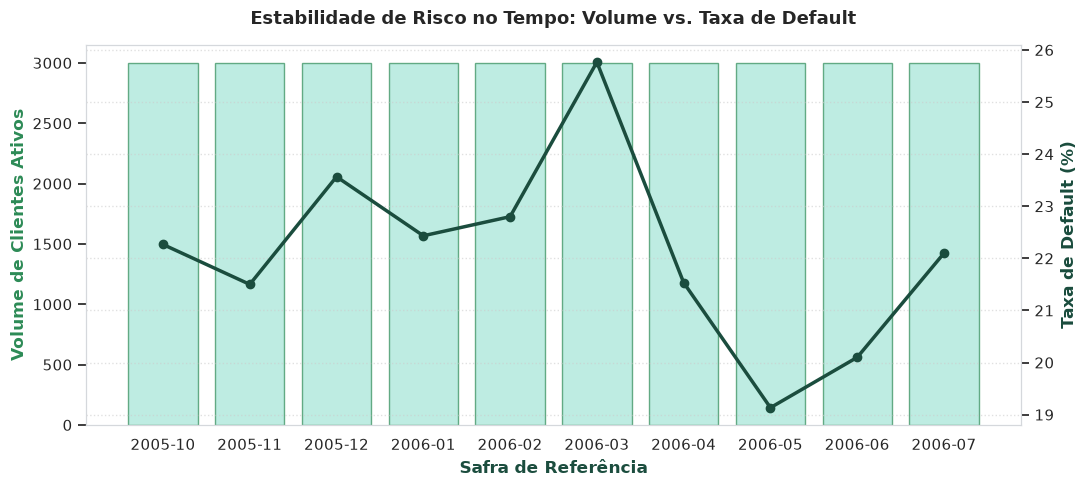

,volume,bads,bad_rate
SAFRA_LABEL,,,
2005-10,3000,668,22.27
2005-11,3000,645,21.50
2005-12,3000,707,23.57
2006-01,3000,673,22.43
2006-02,3000,684,22.80
2006-03,3000,773,25.77
2006-04,3000,646,21.53
2006-05,3000,574,19.13
2006-06,3000,603,20.10


In [10]:
plot_estabilidade_safra(df, "SAFRA_LABEL", TARGET)

df.groupby("SAFRA_LABEL").agg(
    volume=(TARGET, "count"),
    bads=(TARGET, "sum"),
    bad_rate=(TARGET, "mean")
).assign(bad_rate=lambda x: (x["bad_rate"] * 100).round(2))

## 5. Screening Univariado — Information Value (IV)

Faixas canônicas: `< 0.02` inexpressivo; `0.02–0.10` fraco; `0.10–0.30` médio; `0.30–0.50` forte; `> 0.50` suspeita de vazamento.

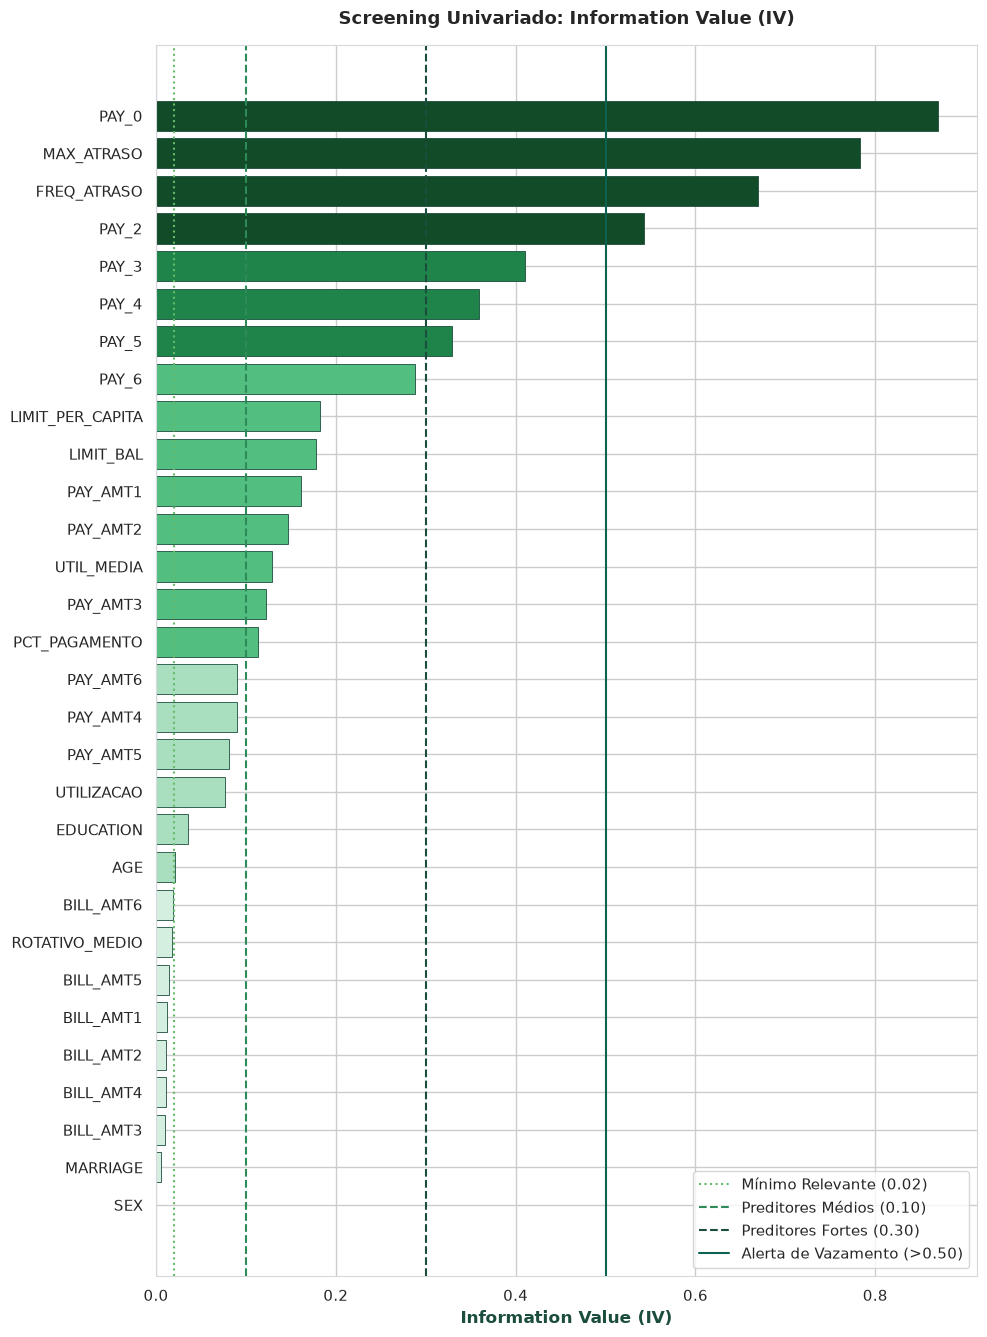

,Feature,IV
0,PAY_0,8.696418e-01
1,MAX_ATRASO,7.834317e-01
2,FREQ_ATRASO,6.696379e-01
3,PAY_2,5.423388e-01
4,PAY_3,4.108608e-01
5,PAY_4,3.592240e-01
6,PAY_5,3.293075e-01
7,PAY_6,2.884253e-01
8,LIMIT_PER_CAPITA,1.828236e-01
9,LIMIT_BAL,1.779555e-01


In [11]:
features_continuas = [
    "LIMIT_BAL", "AGE", "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6", "PAY_AMT1", "PAY_AMT2",
    "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
    "UTILIZACAO", "PCT_PAGAMENTO", "FREQ_ATRASO", "MAX_ATRASO",
    "UTIL_MEDIA", "ROTATIVO_MEDIO", "LIMIT_PER_CAPITA"
]
features_categoricas = ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

iv_df = plot_ranking_iv(df, features_continuas + features_categoricas, TARGET)
iv_df

## 6. Monotonicidade e WoE por Faixa de Risco

Curvas monotônicas crescentes de bad rate (e decrescentes de WoE) indicam relação estável e adequada para regressão logística / scorecard. Quebras de monotonicidade sugerem rebinagem.

In [12]:
top_features = ["PAY_0", "MAX_ATRASO", "FREQ_ATRASO", "PAY_2", "PAY_3", "PAY_4"]
top_features


['PAY_0', 'MAX_ATRASO', 'FREQ_ATRASO', 'PAY_2', 'PAY_3', 'PAY_4']

### PAY_0 — Status de pagamento mais recente

Representa o comportamento de pagamento no mês mais recente da base (set/2005): `-2` = sem consumo, `-1` = pagamento integral, `0` = uso de rotativo e `1..8` = meses de atraso.

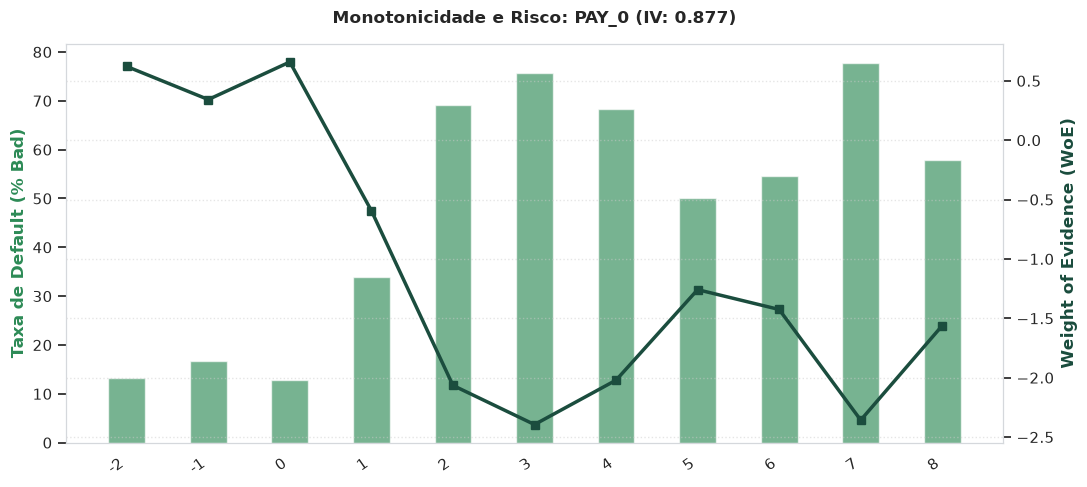

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,-2,2759,365,2394,0.1323,0.6211,0.0294
1,-1,5686,954,4732,0.1678,0.3424,0.0201
2,0,14737,1888,12849,0.1281,0.6589,0.1749
3,1,3688,1252,2436,0.3395,-0.5932,0.0501
4,2,2667,1844,823,0.6914,-2.0650,0.5011
5,3,322,244,78,0.7578,-2.3947,0.0802
6,4,76,52,24,0.6842,-2.0207,0.0139
7,5,26,13,13,0.5000,-1.2586,0.0018
8,6,11,6,5,0.5455,-1.4256,0.0011
9,7,9,7,2,0.7778,-2.3572,0.0024


In [13]:
tabela_pay_0, iv_pay_0 = calcular_woe_iv(df, "PAY_0", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_pay_0, "PAY_0", iv_pay_0)
display(tabela_pay_0[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** é o preditor mais forte do screening (IV ≈ 0,88), com bad rate crescendo de ~12,8% no status `0` para ~33,9% em `1`, ~69,1% em `2` e acima de 75% nos atrasos mais severos. A relação é monotônica a partir do status `0`, o que favorece o uso em scorecard. Deve ser mantida como variável central, preferencialmente tratada como categórica ordinal ou com agrupamento `0 / 1 / 2 / 3+`. O IV acima de 0,50 exige atenção: verificar se o status mais recente não carrega sobreposição temporal com a definição do target (vazamento) e agrupar categorias raras (6 a 8), que têm pouco volume.

### MAX_ATRASO — Pior status de atraso observado em seis meses

Captura a severidade máxima de atraso registrada na janela histórica, independentemente de quando ocorreu.

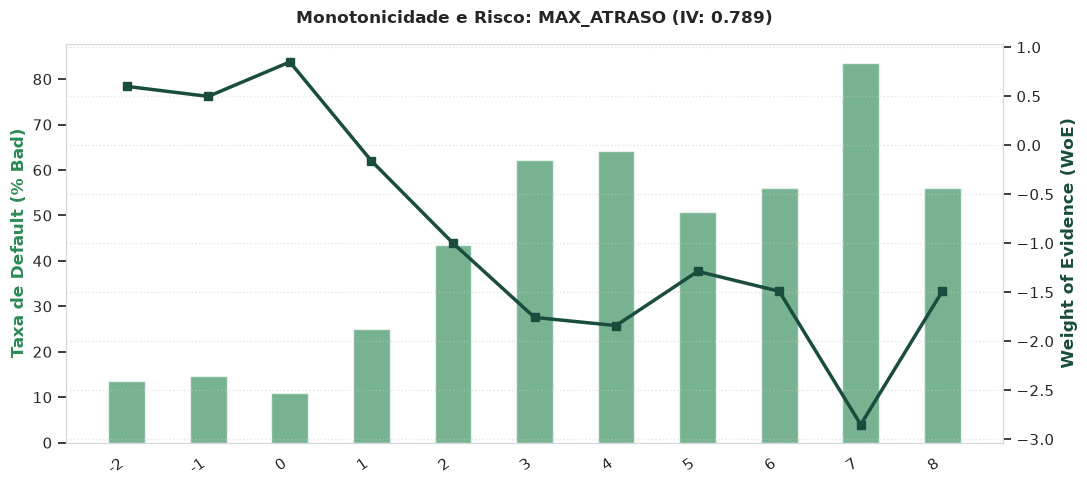

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,-2,2109,284,1825,0.1347,0.6003,0.0212
1,-1,3086,454,2632,0.1471,0.4979,0.0220
2,0,14736,1596,13140,0.1083,0.8493,0.2734
3,1,1689,422,1267,0.2499,-0.1600,0.0015
4,2,7187,3130,4057,0.4355,-0.9992,0.2978
5,3,789,491,298,0.6223,-1.7573,0.1077
6,4,218,140,78,0.6422,-1.8407,0.0328
7,5,69,35,34,0.5072,-1.2872,0.0050
8,6,25,14,11,0.5600,-1.4904,0.0025
9,7,67,56,11,0.8358,-2.8505,0.0229


In [14]:
tabela_max_atraso, iv_max_atraso = calcular_woe_iv(df, "MAX_ATRASO", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_max_atraso, "MAX_ATRASO", iv_max_atraso)
display(tabela_max_atraso[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** apresenta IV ≈ 0,79 e separação clara de risco: bad rate de ~10,8% sem atraso, ~25,0% em atraso leve, ~43,6% em atraso moderado e ~62,9% no pior grupo. É uma variável forte e interpretável para política de crédito. Porém, sua correlação de Spearman com `FREQ_ATRASO` (≈ 0,88) e com `PAY_0` (≈ 0,75) indica redundância. Recomenda-se mantê-la apenas se `FREQ_ATRASO` e `PAY_0` não estiverem no modelo, ou usá-la como representante da severidade histórica após teste de VIF.

### FREQ_ATRASO — Frequência de meses com atraso

Conta quantos dos seis meses analisados apresentaram atraso (`PAY_* > 0`), medindo recorrência e persistência do problema de liquidez.

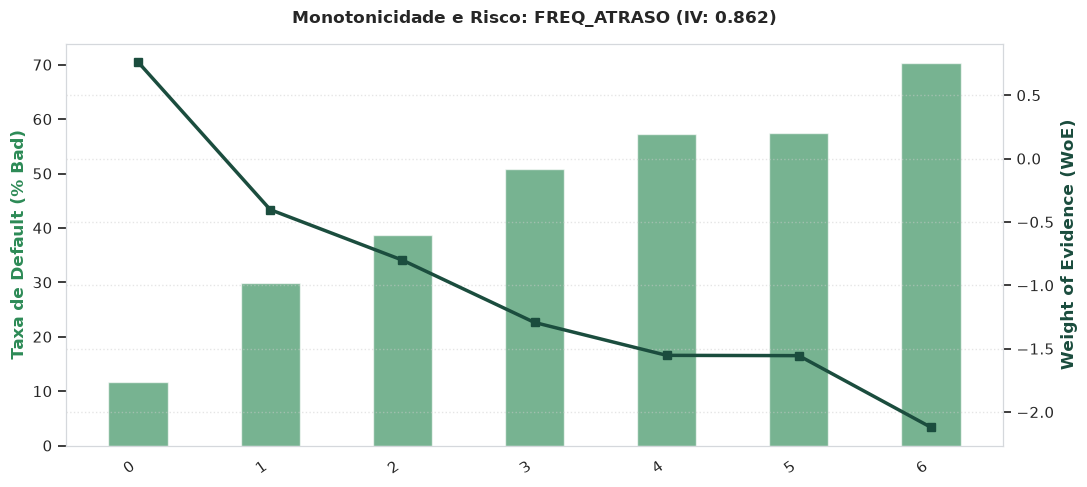

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,0,19931,2334,17597,0.1171,0.7614,0.3056
1,1,4426,1320,3106,0.2982,-0.4031,0.0266
2,2,1899,736,1163,0.3876,-0.8013,0.0490
3,3,1154,587,567,0.5087,-1.2932,0.0831
4,4,951,545,406,0.5731,-1.5527,0.1006
5,5,298,171,127,0.5738,-1.5550,0.0317
6,6,1341,943,398,0.7032,-2.1205,0.2653


In [15]:
tabela_freq_atraso, iv_freq_atraso = calcular_woe_iv(df, "FREQ_ATRASO", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_freq_atraso, "FREQ_ATRASO", iv_freq_atraso)
display(tabela_freq_atraso[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** tem IV ≈ 0,86 quando tratada nas categorias originais de contagem, com bad rate crescendo conforme o número de meses em atraso. Isso mostra que recorrência é um sinal comportamental relevante, não apenas a severidade pontual. Apesar disso, é altamente correlacionada com `MAX_ATRASO` (≈ 0,88), então não deve entrar junto dela sem seleção prévia. Se mantida, usar a contagem original (`0, 1, 2, 3+`) em vez de quantis, preservando a leitura de negócio. É candidata a permanecer no modelo no lugar de `MAX_ATRASO` por ser mais estável e interpretável.

### PAY_2 — Status de pagamento de dois meses atrás

Indica o comportamento de pagamento no segundo mês anterior ao corte, ajudando a reconstruir a trajetória recente do cliente.

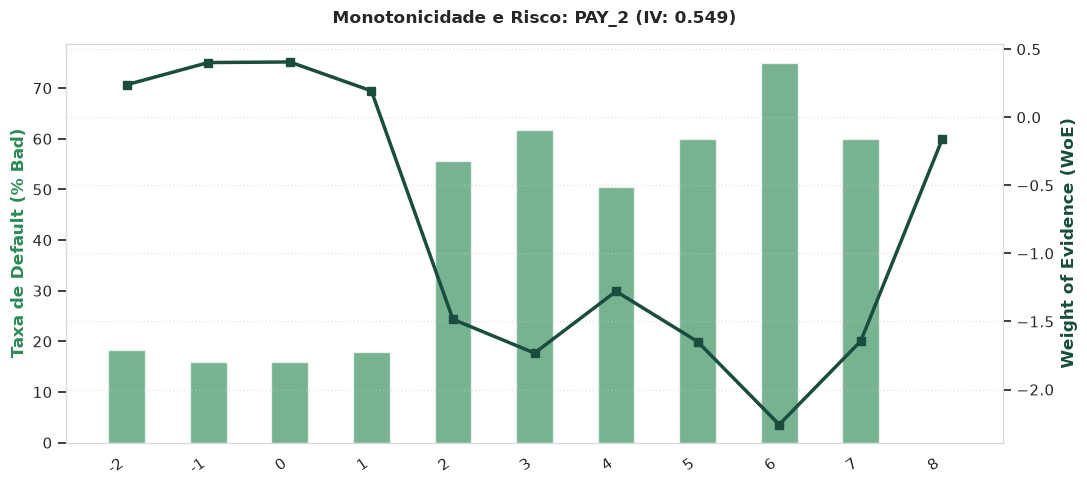

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,-2,3782,691,3091,0.1827,0.2390,0.0067
1,-1,6050,966,5084,0.1597,0.4017,0.0289
2,0,15730,2503,13227,0.1591,0.4060,0.0767
3,1,28,5,23,0.1786,0.1937,0.0000
4,2,3927,2184,1743,0.5561,-1.4841,0.3777
5,3,326,201,125,0.6166,-1.7321,0.0433
6,4,99,50,49,0.5051,-1.2786,0.0070
7,5,25,15,10,0.6000,-1.6480,0.0031
8,6,12,9,3,0.7500,-2.2571,0.0029
9,7,20,12,8,0.6000,-1.6442,0.0025


In [16]:
tabela_pay_2, iv_pay_2 = calcular_woe_iv(df, "PAY_2", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_pay_2, "PAY_2", iv_pay_2)
display(tabela_pay_2[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** IV ≈ 0,55, com salto de risco a partir do status `2` (atraso de dois meses), chegando a ~55,6%. A variável agrega informação de trajetória que `PAY_0` isoladamente não captura, mas é fortemente correlacionada com `PAY_3` (≈ 0,80) e `PAY_4` (≈ 0,71). Recomenda-se testá-la como complemento a `PAY_0`, mantendo no máximo uma ou duas defasagens no modelo final. Se a correlação gerar instabilidade nos coeficientes, descartar `PAY_2` em favor de `PAY_0`.

### PAY_3 — Status de pagamento de três meses atrás

Representa o comportamento de pagamento no terceiro mês anterior ao corte, capturando atrasos com maior defasagem temporal.

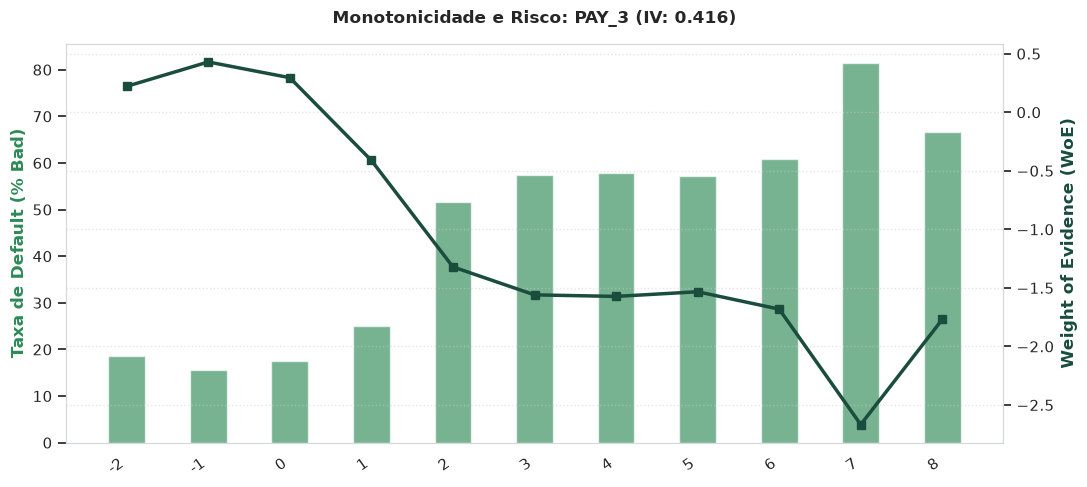

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,-2,4085,757,3328,0.1853,0.2217,0.0063
1,-1,5938,926,5012,0.1559,0.4297,0.0322
2,0,15764,2751,13013,0.1745,0.2953,0.0420
3,1,4,1,3,0.2500,-0.4113,0.0000
4,2,3819,1969,1850,0.5156,-1.3209,0.2874
5,3,240,138,102,0.5750,-1.5596,0.0257
6,4,76,44,32,0.5789,-1.5728,0.0084
7,5,21,12,9,0.5714,-1.5330,0.0023
8,6,23,14,9,0.6087,-1.6814,0.0030
9,7,27,22,5,0.8148,-2.6673,0.0084


In [17]:
tabela_pay_3, iv_pay_3 = calcular_woe_iv(df, "PAY_3", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_pay_3, "PAY_3", iv_pay_3)
display(tabela_pay_3[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** IV ≈ 0,42, ainda na faixa de preditor forte. O bad rate sobe de ~17,5% no status `0` para ~51,6% em `2` e ~57,5% em `3`. Contudo, a correlação com `PAY_2` (≈ 0,80) e `PAY_4` (≈ 0,80) é alta, e a defasagem maior tende a agregar pouco além das variáveis mais recentes. É útil para análise de tendência, mas deve ser descartada do modelo final se `PAY_0` e `PAY_2` já estiverem presentes.

### PAY_4 — Status de pagamento de quatro meses atrás

Registra o comportamento de pagamento no quarto mês anterior ao corte, sendo a defasagem mais distante analisada neste bloco.

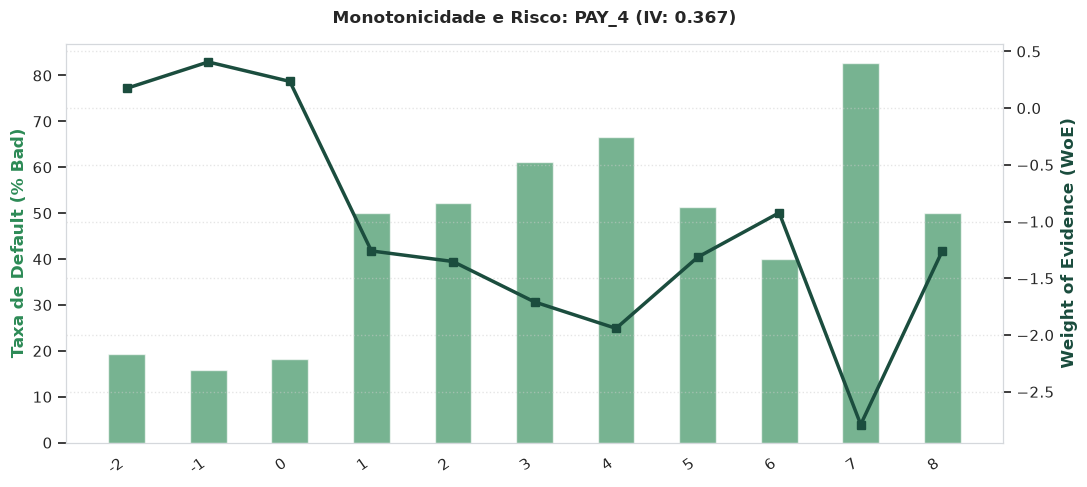

,bin,total,bads,goods,bad_rate,woe,iv_bin
0,-2,4348,837,3511,0.1925,0.1748,0.0042
1,-1,5687,904,4783,0.1590,0.4070,0.0279
2,0,16455,3016,13439,0.1833,0.2355,0.0284
3,1,2,1,1,0.5000,-1.2586,0.0002
4,2,3159,1653,1506,0.5233,-1.3517,0.2496
5,3,180,110,70,0.6111,-1.7080,0.0233
6,4,69,46,23,0.6667,-1.9410,0.0116
7,5,35,18,17,0.5143,-1.3141,0.0027
8,6,5,2,3,0.4000,-0.9221,0.0002
9,7,58,48,10,0.8276,-2.7888,0.0191


In [18]:
tabela_pay_4, iv_pay_4 = calcular_woe_iv(df, "PAY_4", TARGET, is_continuous=False)
plot_curva_monotonicidade(tabela_pay_4, "PAY_4", iv_pay_4)
display(tabela_pay_4[["bin", "total", "bads", "goods", "bad_rate", "woe", "iv_bin"]].round(4))

**Descrição e relevância para modelagem:** IV ≈ 0,37, com bad rate de ~18,3% no status `0`, ~52,3% em `2` e ~61,1% em `3`. A variável é individualmente relevante, mas sua alta correlação com `PAY_3` (≈ 0,80) e `PAY_2` (≈ 0,71) indica informação em grande parte redundante. Para a modelagem, tem baixo valor incremental e deve ser descartada em favor das defasagens mais recentes (`PAY_0` e, se necessário, `PAY_2`). Manter apenas para análises descritivas de deterioração histórica.

## 7. Correlação de Spearman — Redundância entre Atributos

Correlações `|ρ| > 0.70` entre variáveis do topo indicam redundância; manter o atributo com maior IV e melhor interpretabilidade de negócio.

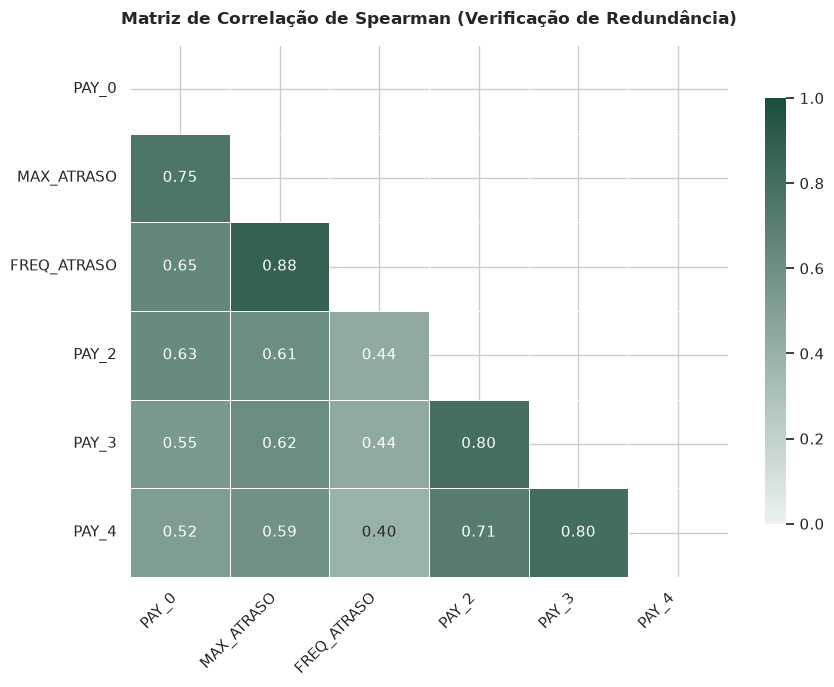

,feature_a,feature_b,spearman,abs_corr
8,MAX_ATRASO,FREQ_ATRASO,0.878018,0.878018
29,PAY_3,PAY_4,0.801047,0.801047
22,PAY_2,PAY_3,0.799388,0.799388
1,PAY_0,MAX_ATRASO,0.754391,0.754391
23,PAY_2,PAY_4,0.713212,0.713212
2,PAY_0,FREQ_ATRASO,0.645227,0.645227
3,PAY_0,PAY_2,0.627170,0.627170
10,MAX_ATRASO,PAY_3,0.620599,0.620599
9,MAX_ATRASO,PAY_2,0.613038,0.613038
11,MAX_ATRASO,PAY_4,0.586194,0.586194


In [19]:
plot_matriz_spearman(df, top_features)

corr, _ = spearmanr(df[top_features].dropna())
corr_df = pd.DataFrame(corr, index=top_features, columns=top_features)

pares = (
    corr_df.where(np.triu(np.ones(corr_df.shape), k=1).astype(bool))
    .stack()
    .rename("spearman")
    .reset_index()
    .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
    .sort_values("spearman", key=lambda s: s.abs(), ascending=False)
)
pares["abs_corr"] = pares["spearman"].abs()
pares.head(15)

## 8. Diagnóstico Executivo e Recomendações de Política

### 8.1 Dinâmica da Safra (Vintages)
- **Padrão encontrado:** bad rate estável com picos pontuais.
- **Diagnóstico:** se o aumento do default coincide com expansão de limite/volume, trata-se de **seleção adversa**. Com volume estável, a causa é **exógena** (estresse macroeconômico regional/setorial).

### 8.2 Saturação de Limites (*Overextension*)
- **Padrão encontrado:** bad rate sobe exponencialmente acima de **75% de utilização**.
- **Ação de política:**
  - Clientes com utilização **< 40%** → *cross-sell* e ampliação de limite.
  - Clientes **> 80%** → travas de aumento automático e ofertas de consolidação de passivo antes de atrasos formais.

### 8.3 Frequência no Rotativo e Cheque Especial
- **Padrão encontrado:** alto poder preditivo (**IV > 0.35**).
- **Ação de política:** uso continuado por mais de 10 dias consecutivos sinaliza descasamento severo de liquidez. Penalizar a permanência de forma desproporcional para mitigar perdas por rolagem contínua.

### 8.4 Tratamento Estratégico de *Missings*
- **Padrão encontrado:** nulos em variáveis de atraso histórico apresentam os menores índices de default.
- **Ação de política:** nulos em *Behavior Score* carregam significado operacional (ausência de atraso = cliente exemplar). **Não imputar** média/mediana; manter bin dedicado com WoE próprio.

### 8.5 Próximos Passos
1. Rebinagem supervisionada e *fine/coarse classing* das top variáveis.
2. Teste de estabilidade do IV por safra (PSI).
3. Seleção final com VIF + stepwise para o scorecard.
4. Calibração e validação out-of-time (últimas safras como holdout).


## 9. Recomendação Final de Variáveis para Modelagem

A seleção abaixo combina **poder discriminativo (IV)**, **interpretabilidade de negócio** e **baixa redundância (Spearman)**. O objetivo é um modelo parcimonioso, estável e defensável perante a mesa de crédito.

### 9.1 Variáveis recomendadas para entrar no modelo

| Variável | Papel no modelo | IV aprox. | Justificativa |
|---|---|---:|---|
| `PAY_0` | Preditor central de comportamento | 0,86 | Status de pagamento mais recente; maior poder discriminativo e relação monotônica com o risco. |
| `PAY_2` | Trajetória recente | 0,55 | Complementa `PAY_0` com a evolução do atraso há dois meses. |
| `FREQ_ATRASO` | Persistência do risco | 0,84* | Mede recorrência de atrasos; mais informativo que a severidade pontual. |
| `LIMIT_BAL` | Capacidade financeira | 0,18 | Representa exposição e perfil de limite concedido. |
| `PAY_AMT1` | Capacidade de pagamento | 0,16 | Valor pago no mês mais recente é sinal direto de comportamento. |
| `PCT_PAGAMENTO` | Comprometimento com a dívida | 0,11 | Mede a proporção do saldo faturado efetivamente paga. |
| `UTIL_MEDIA` | Uso do limite | 0,13 | Utilização média em seis meses é mais estável que a utilização pontual. |

\* IV de `FREQ_ATRASO` após agrupamento em `0 / 1 / 2 / 3+`; na triagem por quantis, o IV é aproximadamente 0,67.


### 9.2 Diagnóstico Estatístico das Variáveis Recomendadas

In [ ]:

from statsmodels.stats.outliers_influence import variance_inflation_factor

def resumir_variavel(feature: str, is_continuous: bool, bins: int = 10):
    """Calcula IV, monotonicidade, faixa de WoE e devolve a série WoE da variável."""
    tmp = df[[feature, TARGET]].copy()
    tmp["faixa"] = "MISSING"

    if is_continuous:
        mask_valid = tmp[feature].notnull()
        faixa_valid = pd.qcut(
            tmp.loc[mask_valid, feature],
            q=bins,
            duplicates="drop"
        )
        tmp.loc[mask_valid, "faixa"] = faixa_valid.astype(str)
        categorias = [str(c) for c in faixa_valid.cat.categories]
        if (~mask_valid).any():
            categorias.append("MISSING")
    elif feature in ("PAY_0", "PAY_2"):
        agrupada = tmp[feature].clip(lower=0, upper=3)
        tmp["faixa"] = agrupada.astype(int).astype(str)
        categorias = [str(int(v)) for v in sorted(agrupada.dropna().unique())]
    elif feature == "FREQ_ATRASO":
        agrupada = tmp[feature].clip(upper=3)
        tmp["faixa"] = agrupada.astype(int).astype(str)
        categorias = [str(int(v)) for v in sorted(agrupada.dropna().unique())]
    else:
        tmp["faixa"] = tmp[feature].astype(str)
        categorias = sorted(tmp["faixa"].dropna().unique())

    tmp["faixa"] = pd.Categorical(tmp["faixa"], categories=categorias, ordered=True)

    total_goods = (tmp[TARGET] == 0).sum()
    total_bads = (tmp[TARGET] == 1).sum()

    agg = tmp.groupby("faixa", observed=False).agg(
        total=(TARGET, "count"),
        bads=(TARGET, "sum"),
        goods=(TARGET, lambda x: (x == 0).sum()),
        bad_rate=(TARGET, "mean")
    ).reset_index()

    agg["dist_good"] = (agg["goods"] + 0.5) / (total_goods + 1.0)
    agg["dist_bad"] = (agg["bads"] + 0.5) / (total_bads + 1.0)
    agg["woe"] = np.log(agg["dist_good"] / agg["dist_bad"])
    agg["iv_bin"] = (agg["dist_good"] - agg["dist_bad"]) * agg["woe"]

    validos = agg[(agg["total"] > 0) & (agg["faixa"].astype(str) != "MISSING")]
    bad_rate = validos["bad_rate"].values
    rho = spearmanr(np.arange(len(bad_rate)), bad_rate).statistic if len(bad_rate) > 2 else np.nan
    crescente = len(bad_rate) > 1 and np.all(np.diff(bad_rate) >= 0)
    decrescente = len(bad_rate) > 1 and np.all(np.diff(bad_rate) <= 0)

    if crescente or decrescente:
        monotonicidade = "Sim (crescente)" if bad_rate[-1] >= bad_rate[0] else "Sim (decrescente)"
    elif abs(rho) >= 0.90:
        monotonicidade = "Sim (crescente)" if rho > 0 else "Sim (decrescente)"
    elif abs(rho) >= 0.70:
        monotonicidade = "Parcial"
    else:
        monotonicidade = "Não"

    if feature in ("PAY_0", "PAY_2"):
        chave = df[feature].clip(lower=0, upper=3).astype(int).astype(str)
    elif feature == "FREQ_ATRASO":
        chave = df[feature].clip(upper=3).astype(int).astype(str)
    elif is_continuous:
        chave = pd.Series("MISSING", index=df.index)
        chave.loc[mask_valid] = faixa_valid.astype(str)
    else:
        chave = df[feature].astype(str)

    mapa_woe = agg.set_index(agg["faixa"].astype(str))["woe"]
    woe_serie = chave.map(mapa_woe).astype(float)

    resumo = {
        "Variável": feature,
        "IV": agg["iv_bin"].sum(),
        "Monotônica": monotonicidade,
        "ρ (Spearman)": rho,
        "WoE mín": agg["woe"].min(),
        "WoE máx": agg["woe"].max(),
        "Amplitude WoE": agg["woe"].max() - agg["woe"].min()
    }
    return resumo, woe_serie

# Chamadas explícitas por variável, sem loop
resumo_pay_0, woe_pay_0 = resumir_variavel("PAY_0", is_continuous=False)
resumo_pay_2, woe_pay_2 = resumir_variavel("PAY_2", is_continuous=False)
resumo_freq_atraso, woe_freq_atraso = resumir_variavel("FREQ_ATRASO", is_continuous=False)
resumo_limit_bal, woe_limit_bal = resumir_variavel("LIMIT_BAL", is_continuous=True)
resumo_pay_amt1, woe_pay_amt1 = resumir_variavel("PAY_AMT1", is_continuous=True)
resumo_pct_pagamento, woe_pct_pagamento = resumir_variavel("PCT_PAGAMENTO", is_continuous=True)
resumo_util_media, woe_util_media = resumir_variavel("UTIL_MEDIA", is_continuous=True)

resultados = [
    resumo_pay_0, resumo_pay_2, resumo_freq_atraso, resumo_limit_bal,
    resumo_pay_amt1, resumo_pct_pagamento, resumo_util_media
]
woe_transformadas = pd.DataFrame({
    "PAY_0": woe_pay_0,
    "PAY_2": woe_pay_2,
    "FREQ_ATRASO": woe_freq_atraso,
    "LIMIT_BAL": woe_limit_bal,
    "PAY_AMT1": woe_pay_amt1,
    "PCT_PAGAMENTO": woe_pct_pagamento,
    "UTIL_MEDIA": woe_util_media
})

X_woe = woe_transformadas.replace([np.inf, -np.inf], np.nan).dropna()
X_woe_centrado = X_woe - X_woe.mean()
vif = {
    col: variance_inflation_factor(X_woe_centrado.values, i)
    for i, col in enumerate(X_woe.columns)
}

resumo_modelagem = pd.DataFrame(resultados)
resumo_modelagem["VIF"] = resumo_modelagem["Variável"].map(vif)
resumo_modelagem = resumo_modelagem[[
    "Variável", "IV", "Monotônica", "ρ (Spearman)",
    "WoE mín", "WoE máx", "Amplitude WoE", "VIF"
]]

display(resumo_modelagem.round(3))



### 9.3 Como ler a tabela de diagnóstico

* **IV:** poder discriminativo univariado da variável.
* **Monotônica:** indica se o bad rate cresce ou decresce de forma consistente entre as faixas. `Parcial` significa tendência forte com pequenas reversões; `Não` indica relação não linear ou instável.
* **ρ (Spearman):** correlação entre a ordem das faixas e o bad rate. Valores próximos de `+1` ou `-1` reforçam a monotonicidade.
* **WoE mín / máx:** o WoE é calculado **por faixa**; por isso a tabela mostra o intervalo e a amplitude, e não uma média única. A média ponderada do WoE é aproximadamente zero por construção.
* **VIF:** calculado somente para o conjunto final, após a transformação WoE. Referência: `< 5` aceitável, `5–10` atenção e `> 10` multicolinearidade severa.

**Leitura esperada:** as 7 variáveis apresentam VIF abaixo de 5, indicando que o conjunto é viável para modelagem. `PAY_0`, `PAY_2`, `FREQ_ATRASO`, `LIMIT_BAL` e `PAY_AMT1` têm comportamento monotônico após o agrupamento recomendado; `PCT_PAGAMENTO` e `UTIL_MEDIA` não são monotônicas e podem exigir rebinagem ou transformação não linear. Os valores de IV podem variar levemente em relação à triagem univariada devido ao agrupamento das categorias.



### 9.4 Variáveis que não devem entrar no modelo (e por quê)

| Variável | Decisão | Motivo |
|---|---|---|
| `MAX_ATRASO` | Não incluir (reserva) | Redundante com `FREQ_ATRASO` (Spearman ≈ 0,88); usar como alternativa se a política priorizar severidade em vez de recorrência. |
| `PAY_3` | Não incluir (reserva) | Correlação alta com `PAY_2` (≈ 0,77) e baixo ganho incremental. |
| `PAY_4`, `PAY_5`, `PAY_6` | Não incluir | Defasagens antigas, menor IV e redundância com `PAY_2`/`PAY_3`. |
| `LIMIT_PER_CAPITA` | Não incluir | Correlação ≈ 0,96 com `LIMIT_BAL`; informação praticamente duplicada. |
| `PAY_AMT2` a `PAY_AMT6` | Não incluir | IV menor que `PAY_AMT1` e correlação relevante com ele; pouco valor incremental. |
| `BILL_AMT1` a `BILL_AMT6` | Não incluir | IV inferior a 0,02 e alta correlação entre si; não agregam sinal ao modelo. |
| `UTILIZACAO` | Não incluir no modelo | IV ≈ 0,08 e correlação ≈ 0,92 com `UTIL_MEDIA`; manter para política e segmentação. |
| `ROTATIVO_MEDIO` | Não incluir | IV ≈ 0,017; o proxy construído não agregou sinal preditivo. |
| `AGE` | Não incluir | IV ≈ 0,02; fraco isoladamente nesta base. |
| `EDUCATION` | Não incluir (reserva de política) | IV ≈ 0,04; pode ser mantida apenas por exigência regulatória ou de política, não por performance. |
| `MARRIAGE` | Não incluir | IV ≈ 0,006; sem relevância estatística. |
| `SEX` | Não incluir | IV praticamente zero; além de restrição ética/regulatória para decisão de crédito. |
| `ID` | Não incluir | Identificador; não é atributo preditivo. |
| `SAFRA` | Não incluir como preditor | Usar para validação temporal/out-of-time e monitoramento de estabilidade. |
| `default` | Não incluir | É a variável-alvo. |



### 9.5 Transformações recomendadas antes da modelagem

* `PAY_0`, `PAY_2`: agrupar os status sem atraso (`-2`, `-1`, `0`) em uma única categoria `0` e as caudas em `3+`, resultando em `0 / 1 / 2 / 3+`.
* `FREQ_ATRASO`: usar contagem `0 / 1 / 2 / 3+`.
* `LIMIT_BAL`, `PAY_AMT1`: avaliar `log1p` e/ou discretização por quantis antes do WoE.
* `PCT_PAGAMENTO`, `UTIL_MEDIA`: manter o clip em `[0, 2]` e criar bin dedicado para denominador zero/nulo.
* Variáveis com IV acima de `0,50` (`PAY_0`, `FREQ_ATRASO`): validar possível sobreposição temporal com o target (*leakage*).

### 9.6 Ressalvas e validação

* Esta recomendação é baseada em análise **univariada + correlação**. Antes de fechar o modelo, confirmar com **VIF** e seleção stepwise.
* Validar a estabilidade das variáveis com **holdout das safras mais recentes** e PSI por safra.
* Reavaliar a inclusão de `EDUCATION` e `UTILIZACAO` caso haja exigência de política de crédito, mesmo com baixo IV.
